# Can image embeddings predict detector validity?

Analysis of frozen-feature assessors predicting **1 − LRP** for YOLO and RF-DETR.
All reported results are on **assessor validation**, not the assessor test partition.

The saved experiment uses 5,499 training images, 2,092 validation images in 460 geographic tiles,
and seed 43. Seven encoders were available; DINOv3 was blocked by gated model access.
This is exploratory screening: selecting the best of many configurations on this validation set
makes their reported performance optimistic. Repeated seeds and final held-out testing remain necessary.

Run all cells from the root Poetry environment. This notebook reads existing artifacts and does
not train models or evaluate assessor-test labels. Figures and analysis tables are exported directly
to `results/assessors/`.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src/assessors').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/assessors').exists(), 'Open from the repository root or notebooks/'
RESULTS = ROOT / 'results/assessors'
RUNS = ROOT / 'models/assessors'
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 16)

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / f'analysis_{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

summary = pd.read_csv(RESULTS / 'summary.csv')
df = summary.query("split == 'val' and target == 'lrp'").copy()
assert len(df) and not df.duplicated(['run', 'detector']).any()
configs = {r: json.loads((RUNS / r / 'config.json').read_text()) for r in df.run.unique()}

def describe(run):
    c = configs[run]
    if c['regressor'] == 'constant':
        return 'constant', 'none', 'constant'
    name = Path(c['features']).stem
    if name == 'quality':
        return 'image_quality', 'none', c['regressor']
    encoder, pool = name.rsplit('-', 1)
    return encoder, pool, c['regressor']

df[['encoder', 'pool', 'regressor']] = [describe(r) for r in df.run]
detectors = sorted(df.detector.unique())
metrics = ['mae', 'r2', 'ece', 'spearman', 'aurc']
all_results = df[['detector', 'encoder', 'pool', 'regressor', 'seed', *metrics,
                  'mae_ci_low', 'mae_ci_high']].sort_values(['detector', 'encoder', 'pool', 'regressor'])
all_results.to_csv(RESULTS / 'analysis_all_results.csv', index=False)
print(f'{len(df)} configurations; detectors: {detectors}; seeds: {sorted(df.seed.unique())}')
display(df.groupby('detector')[['train_images', 'images', 'groups']].first())
display(all_results.round(4))


90 configurations; detectors: ['rf-detr', 'yolo']; seeds: [43]


,train_images,images,groups
detector,,,
rf-detr,5499,2092,460
yolo,5499,2092,460


,detector,encoder,pool,regressor,seed,mae,r2,ece,spearman,aurc,mae_ci_low,mae_ci_high
88,rf-detr,constant,none,constant,43,0.1455,-0.0017,0.0075,NaN,0.4830,0.1374,0.1539
0,rf-detr,convnext_tiny,global,mlp,43,0.1298,0.1737,0.0171,0.4275,0.4084,0.1237,0.1383
2,rf-detr,convnext_tiny,global,ridge,43,0.1370,0.1057,0.0339,0.3802,0.4160,0.1314,0.1442
4,rf-detr,convnext_tiny,mean,mlp,43,0.1287,0.1760,0.0178,0.4334,0.4045,0.1220,0.1371
6,rf-detr,convnext_tiny,mean,ridge,43,0.1362,0.1160,0.0339,0.3872,0.4142,0.1301,0.1440
8,rf-detr,convnext_tiny,spatial,mlp,43,0.5170,-7.7799,0.5170,NaN,0.4685,0.5041,0.5308
10,rf-detr,convnext_tiny,spatial,ridge,43,0.1919,-0.6678,0.1289,0.2308,0.4413,0.1860,0.1985
12,rf-detr,dinov2,global,mlp,43,0.1298,0.1572,0.0218,0.4339,0.4079,0.1237,0.1396
14,rf-detr,dinov2,global,ridge,43,0.1336,0.1299,0.0315,0.4041,0.4104,0.1274,0.1423
16,rf-detr,dinov2,mean,mlp,43,0.1275,0.1825,0.0177,0.4528,0.4081,0.1213,0.1362


## Reading the metrics

- **R²**: explained variance relative to a constant equal to the evaluation-set target mean; negative values are worse than that reference.
- **MAE**: mean absolute error in validity units, on [0, 1].
- **ECE**: prediction-weighted absolute gap between mean prediction and mean continuous target in 25 equal-width bins.
- **Spearman**: rank association with measured validity.
- **AURC**: mean LRP error across retained prefixes sorted by descending predicted validity; lower is better.

A constant can have excellent ECE while providing no image-level discrimination. Compare AURC
methods **within a detector**: differences between detectors also reflect differences in their underlying error rates.
The existing MAE intervals bootstrap geographic tiles; they do not capture seed or model-selection uncertainty.


In [2]:
# Load only validation predictions, preserving an identical image order for paired comparisons.
predictions = {}
checks = []
for row in df.itertuples():
    p = pd.read_csv(RUNS / row.run / 'predictions.csv')
    p = p[(p.split == 'val') & (p.detector == row.detector)].sort_values('image_id').reset_index(drop=True)
    assert len(p) == row.images and p.image_id.is_unique
    assert np.isfinite(p[['actual', 'predicted']]).all().all()
    predictions[row.run] = p
    checks.append({'run': row.run, 'prediction_std': p.predicted.std(ddof=0),
                   'prediction_min': p.predicted.min(), 'prediction_max': p.predicted.max(),
                   'near_boundary_fraction': ((p.predicted < .001) | (p.predicted > .999)).mean()})
df = df.merge(pd.DataFrame(checks), on='run', validate='one_to_one')
df['collapsed'] = (df.regressor == 'mlp') & (df.prediction_std < 1e-8)
for detector in detectors:
    selected = df[df.detector == detector]
    reference = predictions[selected.iloc[0].run]
    for run in selected.run:
        p = predictions[run]
        assert p.image_id.equals(reference.image_id)
        assert np.allclose(p.actual, reference.actual)
        assert p.group.equals(reference.group)

# Deduplicate global/mean pooling only where cached arrays are exactly identical.
feature_dir = ROOT / 'data/assessors/features/224x448-grid2x4'
duplicate_encoders = []
for encoder in ['resnet18', 'resnet50', 'mobilenet_v3_small']:
    global_path, mean_path = [feature_dir / f'{encoder}-{pool}.npz' for pool in ['global', 'mean']]
    with np.load(global_path) as a, np.load(mean_path) as b:
        equal = np.array_equal(a['image_id'], b['image_id']) and np.array_equal(a['features'], b['features'])
    if equal:
        duplicate_encoders.append(encoder)
df['duplicate_pool'] = df.encoder.isin(duplicate_encoders) & (df.pool == 'mean')
unique = df[~df.duplicate_pool].copy()
print('Encoders with identical global/mean features:', duplicate_encoders)
print('All runs:', len(df), '| distinct feature configurations:', len(unique))
print('Collapsed MLP runs:', int(df.collapsed.sum()))
display(df[df.collapsed][['detector', 'encoder', 'pool', 'mae', 'r2',
                         'prediction_min', 'prediction_max', 'near_boundary_fraction']])


Encoders with identical global/mean features: ['resnet18', 'resnet50', 'mobilenet_v3_small']
All runs: 90 | distinct feature configurations: 78
Collapsed MLP runs: 2


,detector,encoder,pool,mae,r2,prediction_min,prediction_max,near_boundary_fraction
8,rf-detr,convnext_tiny,spatial,0.517022,-7.779920,9.933776e-22,1.522456e-10,1.0
20,rf-detr,dinov2,spatial,0.482978,-6.789117,1.000000e+00,1.000000e+00,1.0


## Encoder and pooling landscape

The heatmaps retain failed runs and duplicated pooling variants so the full experiment is visible.
Colour is clipped at R² = −0.3 for readability; the annotations show the actual values.


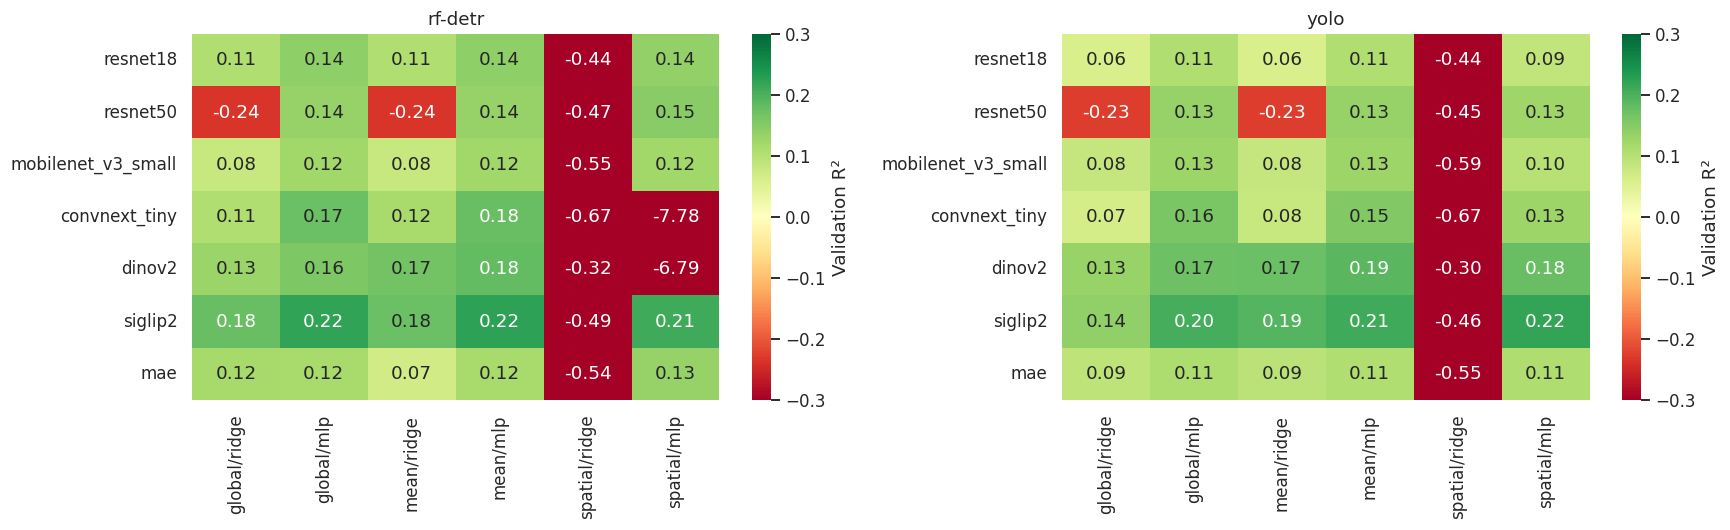

In [3]:
encoders = ['resnet18', 'resnet50', 'mobilenet_v3_small', 'convnext_tiny', 'dinov2', 'siglip2', 'mae']
columns = [f'{pool}/{reg}' for pool in ['global', 'mean', 'spatial'] for reg in ['ridge', 'mlp']]
fig, axes = plt.subplots(1, len(detectors), figsize=(16, 5), squeeze=False)
for ax, detector in zip(axes[0], detectors):
    part = df[(df.detector == detector) & df.encoder.isin(encoders)].copy()
    part['variant'] = part.pool + '/' + part.regressor
    table = part.pivot(index='encoder', columns='variant', values='r2').reindex(index=encoders, columns=columns)
    sns.heatmap(table, annot=True, fmt='.2f', cmap='RdYlGn', vmin=-.3, vmax=.3,
                center=0, ax=ax, cbar_kws={'label': 'Validation R²'})
    ax.set(title=detector, xlabel='', ylabel='')
show_figure(fig, 'r2_heatmaps')


,detector,encoder,pool,regressor,mae,r2,ece,spearman,aurc,mae_reduction_pct
4,rf-detr,convnext_tiny,mean,mlp,0.1287,0.1760,0.0178,0.4334,0.4045,11.4899
16,rf-detr,dinov2,mean,mlp,0.1275,0.1825,0.0177,0.4528,0.4081,12.3462
32,rf-detr,mae,spatial,mlp,0.1325,0.1348,0.0194,0.3886,0.4179,8.8825
36,rf-detr,mobilenet_v3_small,global,mlp,0.1337,0.1241,0.0204,0.3714,0.4168,8.0946
52,rf-detr,resnet18,global,mlp,0.1330,0.1414,0.0129,0.3923,0.4160,8.5644
72,rf-detr,resnet50,spatial,mlp,0.1333,0.1455,0.0161,0.3972,0.4146,8.3767
80,rf-detr,siglip2,mean,mlp,0.1256,0.2235,0.0164,0.4813,0.4005,13.6548
1,yolo,convnext_tiny,global,mlp,0.1304,0.1610,0.0116,0.3981,0.4671,9.5674
17,yolo,dinov2,mean,mlp,0.1281,0.1878,0.0166,0.4359,0.4602,11.1775
25,yolo,mae,global,mlp,0.1352,0.1102,0.0120,0.3199,0.4805,6.2865


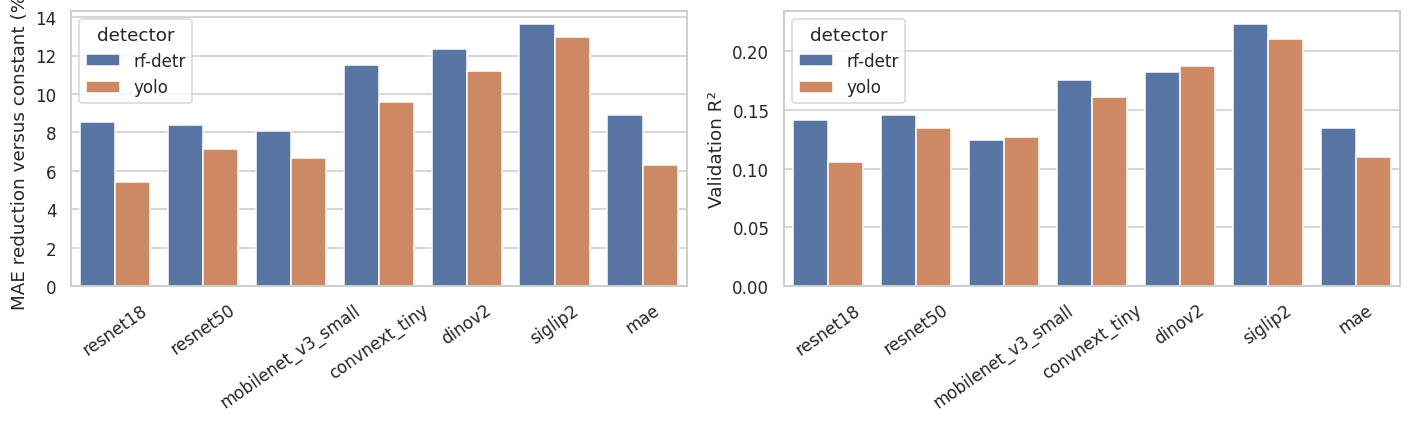

In [4]:
# Best MAE within each encoder is a validation-selected summary, not an unbiased ranking.
learned = unique[unique.encoder.isin(encoders)]
best = learned.loc[learned.groupby(['detector', 'encoder']).mae.idxmin()].copy()
constant = df[df.regressor == 'constant'].set_index('detector')
best['mae_reduction_pct'] = [100*(1-r.mae/constant.loc[r.detector, 'mae']) for r in best.itertuples()]
best.to_csv(RESULTS / 'analysis_best_per_encoder.csv', index=False)
display(best[['detector', 'encoder', 'pool', 'regressor', *metrics, 'mae_reduction_pct']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=best, x='encoder', y='mae_reduction_pct', hue='detector', order=encoders, ax=axes[0])
sns.barplot(data=best, x='encoder', y='r2', hue='detector', order=encoders, ax=axes[1])
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
    ax.set_xlabel('')
axes[0].set_ylabel('MAE reduction versus constant (%)')
axes[1].set_ylabel('Validation R²')
show_figure(fig, 'best_encoders')


## Paired regressor and pooling comparisons

Pair methods on the same detector, encoder and pooling rather than averaging unrelated runs.
Duplicated global/mean CNN features are counted once. Negative MAE differences favour the method
named first. Failed optimizations are included in the primary comparison and flagged explicitly.


,pairs,mlp_wins,median_mae_difference,collapsed_mlps
detector,,,,
rf-detr,18,15,-0.004768,2
yolo,18,18,-0.007411,0


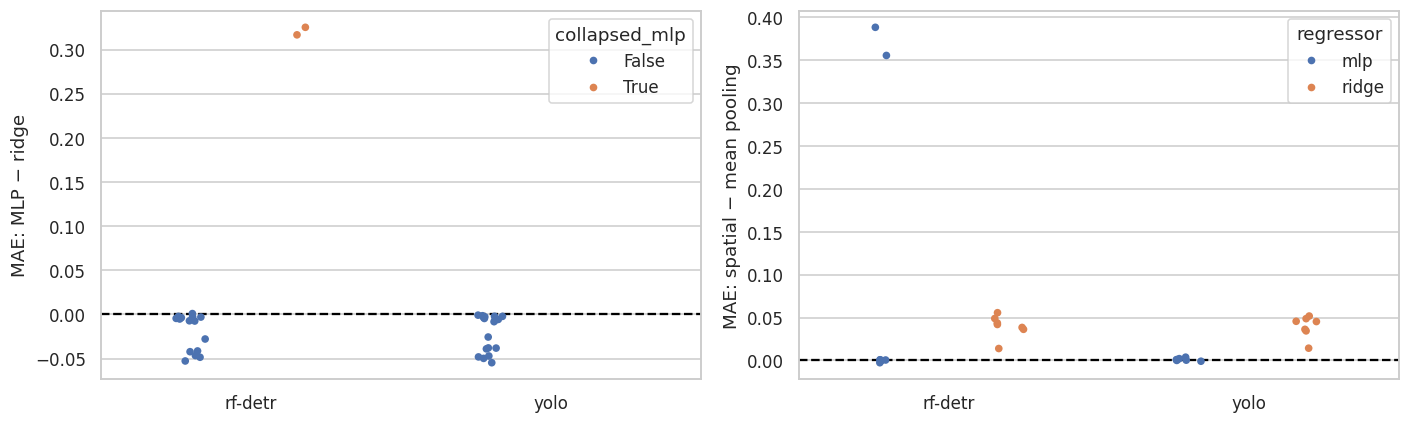

In [5]:
paired = unique[unique.encoder.isin(encoders)].pivot(
    index=['detector', 'encoder', 'pool'], columns='regressor', values=['mae', 'collapsed'])
regressor_effect = (paired['mae']['mlp'] - paired['mae']['ridge']).rename('mlp_minus_ridge').reset_index()
regressor_effect['collapsed_mlp'] = paired['collapsed']['mlp'].to_numpy()
regressor_effect.to_csv(RESULTS / 'analysis_regressor_pairs.csv', index=False)
display(regressor_effect.groupby('detector').agg(
    pairs=('mlp_minus_ridge', 'size'), mlp_wins=('mlp_minus_ridge', lambda x: int((x < 0).sum())),
    median_mae_difference=('mlp_minus_ridge', 'median'), collapsed_mlps=('collapsed_mlp', 'sum')))

pool_pairs = df[df.encoder.isin(encoders) & df.pool.isin(['mean', 'spatial'])].pivot(
    index=['detector', 'encoder', 'regressor'], columns='pool', values='mae')
pool_effect = (pool_pairs.spatial-pool_pairs['mean']).rename('spatial_minus_mean').reset_index()
pool_effect.to_csv(RESULTS / 'analysis_pooling_pairs.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.stripplot(data=regressor_effect, x='detector', y='mlp_minus_ridge', hue='collapsed_mlp',
              dodge=True, jitter=.1, ax=axes[0])
sns.stripplot(data=pool_effect, x='detector', y='spatial_minus_mean', hue='regressor',
              dodge=True, jitter=.1, ax=axes[1])
for ax in axes:
    ax.axhline(0, color='black', linestyle='--')
    ax.set_xlabel('')
axes[0].set_ylabel('MAE: MLP − ridge')
axes[1].set_ylabel('MAE: spatial − mean pooling')
show_figure(fig, 'paired_effects')


Spatial vectors have more dimensions and also produce larger MLP heads. This experiment therefore
compares complete feature–assessor configurations, not spatial information in isolation.
Poor spatial ridge results may reflect inadequate regularization or limited training data; they do
not establish that spatial information is unhelpful. The saturated MLPs likewise require an optimization check.


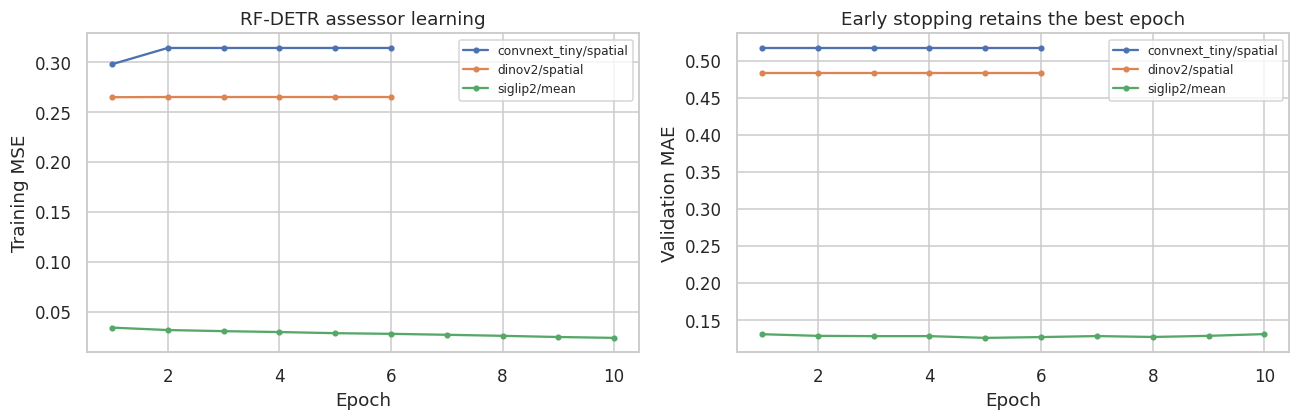

In [6]:
# Learning curves: the two saturated RF-DETR MLPs versus a successful configuration.
winners = df.loc[df.groupby('detector').mae.idxmin()].copy()
curve_runs = list(df[df.collapsed].run) + [winners.set_index('detector').loc['rf-detr', 'run']]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run in curve_runs:
    row = df.set_index('run').loc[run]
    h = pd.read_csv(RUNS / run / 'history.csv')
    label = f'{row.encoder}/{row.pool}'
    axes[0].plot(h.epoch, h.train_mse, marker='.', label=label)
    axes[1].plot(h.epoch, h.val_mae, marker='.', label=label)
axes[0].set(xlabel='Epoch', ylabel='Training MSE', title='RF-DETR assessor learning')
axes[1].set(xlabel='Epoch', ylabel='Validation MAE', title='Early stopping retains the best epoch')
for ax in axes:
    ax.legend(fontsize=8)
show_figure(fig, 'learning_failures')


## Calibration versus predictability

ECE can be small simply because all images receive almost the same predicted score.
A useful assessor must improve prediction error and ranking as well. Inspect reliability diagrams
with their bin populations; sparse bins provide noisy estimates.


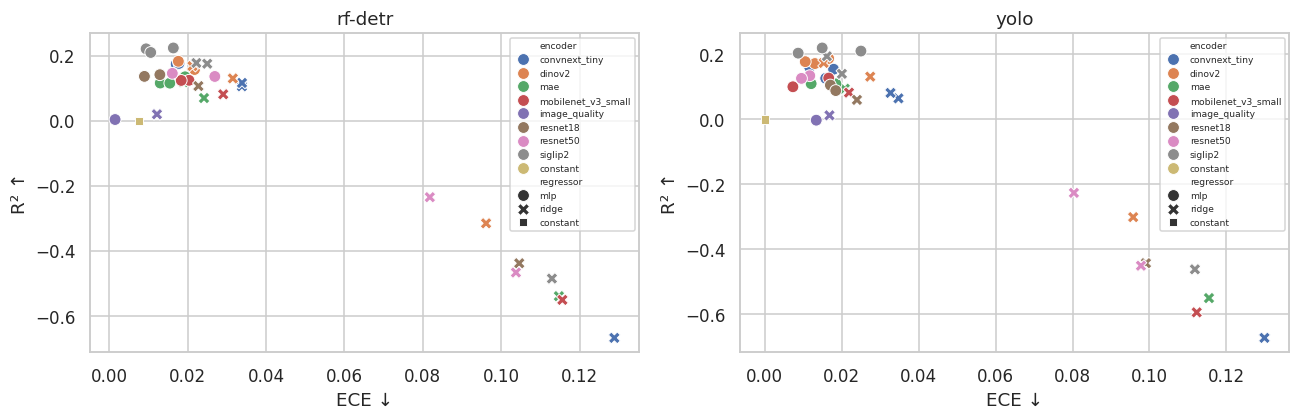

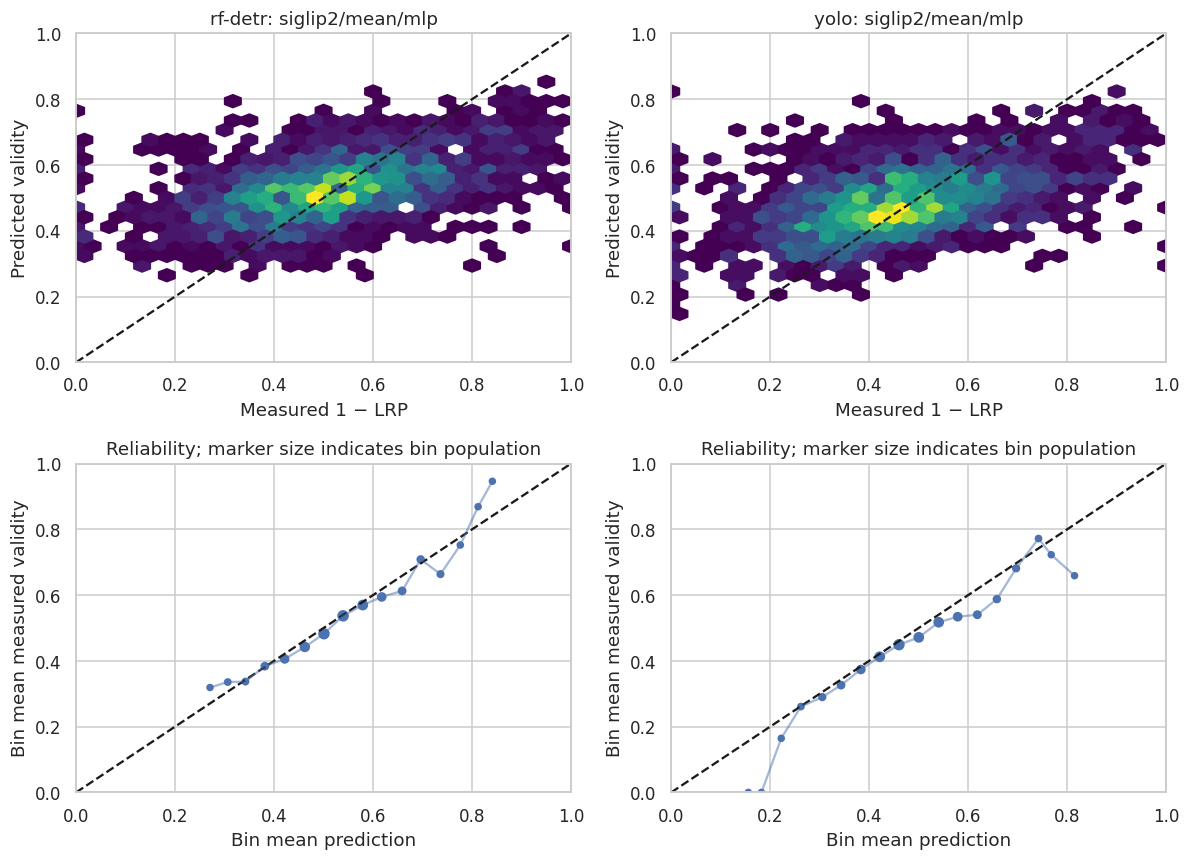

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, detector in zip(axes, detectors):
    part = unique[(unique.detector == detector) & ~unique.collapsed]
    sns.scatterplot(data=part, x='ece', y='r2', hue='encoder', style='regressor', ax=ax, s=60)
    ax.set(title=detector, xlabel='ECE ↓', ylabel='R² ↑')
    ax.legend(fontsize=6, loc='best')
show_figure(fig, 'calibration_vs_prediction')

fig, axes = plt.subplots(2, len(detectors), figsize=(11, 8))
for j, detector in enumerate(detectors):
    winner = winners[winners.detector == detector].iloc[0]
    p = predictions[winner.run]
    axes[0, j].hexbin(p.actual, p.predicted, gridsize=30, mincnt=1, extent=(0,1,0,1), cmap='viridis')
    axes[0, j].plot([0,1], [0,1], 'k--')
    axes[0, j].set(xlabel='Measured 1 − LRP', ylabel='Predicted validity',
                   title=f'{detector}: {winner.encoder}/{winner.pool}/{winner.regressor}', xlim=(0,1), ylim=(0,1))
    b = p.assign(bin=np.minimum((p.predicted*25).astype(int),24)).groupby('bin').agg(
        actual=('actual','mean'), predicted=('predicted','mean'), images=('actual','size'))
    ax = axes[1, j]
    ax.plot([0,1], [0,1], 'k--')
    ax.scatter(b.predicted, b.actual, s=15+150*b.images/len(p))
    ax.plot(b.predicted, b.actual, alpha=.5)
    ax.set(xlabel='Bin mean prediction', ylabel='Bin mean measured validity', xlim=(0,1), ylim=(0,1),
           title='Reliability; marker size indicates bin population')
show_figure(fig, 'winner_predictions')


## Can the assessor identify easier images?

At coverage 0.5, accept the half of validation images with highest predicted validity and measure
their mean actual LRP. The oracle ranks using measured validity and is only a reference.
Exact prediction ties use expected risk within the tied block, matching the screening implementation.


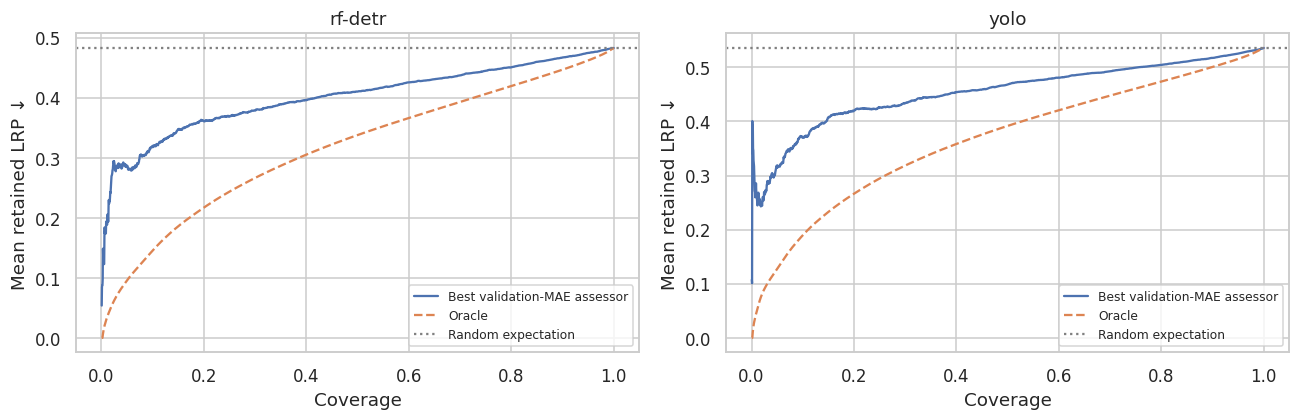

,detector,coverage,retained_lrp,random_lrp,relative_risk_reduction_pct
0,rf-detr,0.25,0.3686,0.4830,23.6805
1,rf-detr,0.50,0.4104,0.4830,15.0338
2,rf-detr,0.75,0.4451,0.4830,7.8511
3,rf-detr,1.00,0.4830,0.4830,-0.0000
4,yolo,0.25,0.4259,0.5358,20.5069
5,yolo,0.50,0.4682,0.5358,12.6152
6,yolo,0.75,0.4993,0.5358,6.8132
7,yolo,1.00,0.5358,0.5358,0.0000


In [8]:
def risk_curve(p):
    ordered = p.sort_values('predicted', ascending=False)
    risk = (1-ordered.actual).groupby(ordered.predicted).transform('mean').to_numpy()
    return np.cumsum(risk)/np.arange(1,len(risk)+1)

coverage_rows = []
fig, axes = plt.subplots(1, len(detectors), figsize=(12,4))
for ax, detector in zip(axes, detectors):
    winner = winners[winners.detector == detector].iloc[0]
    p = predictions[winner.run]
    coverage = np.arange(1,len(p)+1)/len(p)
    curve = risk_curve(p)
    risk = 1-p.actual.to_numpy()
    ax.plot(coverage, curve, label='Best validation-MAE assessor')
    ax.plot(coverage, np.cumsum(np.sort(risk))/np.arange(1,len(p)+1), '--', label='Oracle')
    ax.axhline(risk.mean(), color='gray', linestyle=':', label='Random expectation')
    ax.set(title=detector, xlabel='Coverage', ylabel='Mean retained LRP ↓')
    ax.legend(fontsize=8)
    for fraction in [.25,.5,.75,1.]:
        k=max(1,int(np.ceil(fraction*len(p))))
        coverage_rows.append({'detector':detector, 'coverage':k/len(p), 'retained_lrp':curve[k-1],
                              'random_lrp':risk.mean(), 'relative_risk_reduction_pct':100*(1-curve[k-1]/risk.mean())})
show_figure(fig, 'risk_coverage')
coverage_table = pd.DataFrame(coverage_rows)
coverage_table.to_csv(RESULTS / 'analysis_coverage.csv', index=False)
display(coverage_table.round(4))


## Paired uncertainty by geography

Resample geographic tiles, using identical resampled images for both methods. This estimates
uncertainty in the **paired MAE difference**, conditional on the fitted models and selected validation
configurations. It is not a model-selection-adjusted significance test and does not measure seed variation.


In [9]:
def paired_interval(a, b, repeats=2000, seed=43):
    assert a.image_id.equals(b.image_id)
    paired = pd.DataFrame({'group':a.group, 'difference':abs(a.predicted-a.actual)-abs(b.predicted-b.actual)})
    groups = paired.groupby('group').difference.agg(['sum','count'])
    rng = np.random.default_rng(seed)
    draw = rng.integers(len(groups),size=(repeats,len(groups)))
    samples = groups['sum'].to_numpy()[draw].sum(1)/groups['count'].to_numpy()[draw].sum(1)
    return paired.difference.mean(), *np.quantile(samples,[.025,.975])

comparisons = []
for detector in detectors:
    part = unique[unique.detector == detector]
    winner = winners[winners.detector == detector].iloc[0]
    baseline = part[part.regressor == 'constant'].iloc[0]
    dino = part[part.encoder == 'dinov2'].sort_values('mae').iloc[0]
    for other, label in [(baseline,'constant'),(dino,'best DINOv2')]:
        delta, low, high = paired_interval(predictions[winner.run],predictions[other.run])
        comparisons.append({'detector':detector,'comparison':f'best MAE − {label}',
                            'mae_difference':delta,'paired_ci_low':low,'paired_ci_high':high})
comparison_table=pd.DataFrame(comparisons)
comparison_table.to_csv(RESULTS / 'analysis_paired_intervals.csv',index=False)
display(comparison_table.round(5))


,detector,comparison,mae_difference,paired_ci_low,paired_ci_high
0,rf-detr,best MAE − constant,-0.01986,-0.02424,-0.01573
1,rf-detr,best MAE − best DINOv2,-0.00190,-0.00396,0.00005
2,yolo,best MAE − constant,-0.01871,-0.02351,-0.01430
3,yolo,best MAE − best DINOv2,-0.00259,-0.00593,0.00077


## Observed trends and next experiments

1. **SigLIP 2 leads this screen on both detectors.** Its mean-patch MLP has the lowest MAE; its spatial MLP has the highest YOLO R². The paired geographic-bootstrap intervals for its MAE advantage over the best DINOv2 include zero on both detectors; the lead is not resolved by this screen.
2. **Modern frozen features help, but prediction remains modest.** The best R² is about 0.21–0.22 and Spearman about 0.47–0.48. This supports investigating representation adaptation, not a claim that difficulty is already well predicted.
3. **MLPs generally beat the current ridge configurations.** After deduplicating identical CNN pools, MLP wins 18/18 YOLO pairs and 15/18 RF-DETR pairs. Account for the two saturated runs.
4. **Spatial pooling does not consistently improve the results.** Spatial ridge is especially weak, while successful spatial MLPs are often close to pooled MLPs. Tune ridge regularization and stabilize the MLP before attributing this to the encoder.
5. **Basic CNNs retain useful signal.** They usually beat constant and simple image-quality predictors, though SigLIP 2 and DINOv2 are stronger in this screen.
6. **Small ECE does not imply useful prediction.** The constant baseline illustrates this directly. Keep R², MAE, ranking and risk–coverage alongside calibration.
7. **Ranking offers a practical benefit:** at 50% coverage, the selected assessors reduce retained LRP relative to random acceptance by about 12.6% for YOLO and 15.0% for RF-DETR.
8. **The ordering is similar across YOLO and RF-DETR**, but this does not establish cross-detector transfer: assessors were fitted separately.

Next: stabilize the failed spatial MLPs and test a wider ridge alpha range; repeat shortlisted frozen
methods across seeds; compare partial/full adaptation of SigLIP 2, DINOv2 and a basic CNN with
matched heads and training budgets; add DINOv3 when available. Keep assessor test for the final
predeclared comparison. Geographic tiles are disjoint but adjacent tiles can still be nearby;
stronger drive grouping or a geographic buffer is a useful robustness check.


In [10]:
print('Validation-MAE winners:')
display(winners[['detector','encoder','pool','regressor',*metrics]].round(4))
print(f'Exported analysis tables and figures to {RESULTS}')


Validation-MAE winners:
Exported analysis tables and figures to /home/felix/JEPA-Assessors-OD/results/assessors


,detector,encoder,pool,regressor,mae,r2,ece,spearman,aurc
80,rf-detr,siglip2,mean,mlp,0.1256,0.2235,0.0164,0.4813,0.4005
81,yolo,siglip2,mean,mlp,0.1255,0.2106,0.0250,0.4652,0.4544
